# 02 · Discounting models, a heuristic and machine learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/academic-research/time-preference-choice-models/notebooks/02_models_vs_machine_learning.ipynb)

Four models are fitted to every participant: exponential, hyperbolic and quasi-hyperbolic
discounting, and the ITCH heuristic. Gradient boosting is trained on everyone at once. Each
participant's trials are split into four folds, so every choice is predicted by a model that never
saw it.

The yardstick is completeness (Fudenberg et al. 2022), the share of the predictable variation a model
captures. 0% means no better than the person's base rate; 100% means as good as the true choice
probability, which is known here only because the data are simulated.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "academic-research/time-preference-choice-models"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "timepref").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: time-preference-choice-models


In [2]:
from timepref import config as C, data, quality as Q, models as M, evaluate as E, effects as F, nlp as N, reporting as R

if not (Path("data") / "trials.csv.gz").exists():
    data.save(data.generate(), Path("data"))
tables = data.load(Path("data"))
clean, quality_log, rules = Q.apply(tables)
print(f"{clean['pid'].nunique()} participants, {len(clean):,} choices after exclusions")

399 participants, 23,940 choices after exclusions


## Fits on all data and parameter recovery

Small weak penalties keep estimates finite for people who always pick one side. For participants who
really are hyperbolic discounters, the estimated log k tracks the true value closely.

correlation of true and estimated log k: 0.968
mean error: -0.233 (the fitted model has no magnitude effect)


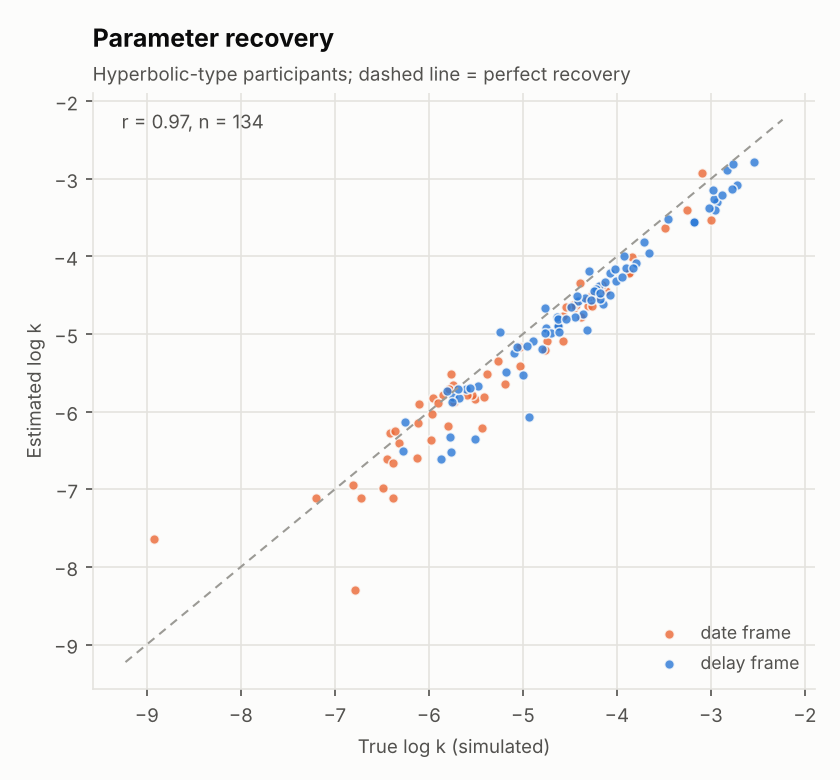

In [3]:
fits = M.fit_all(clean)
h = fits.query("model == 'hyperbolic'").merge(tables["truth"].query("type == 'hyperbolic'"), on="pid")
print("correlation of true and estimated log k:", round(np.corrcoef(h["log_k"], h["theta0"])[0, 1], 3))
print("mean error:", round((h["theta0"] - h["log_k"]).mean(), 3), "(the fitted model has no magnitude effect)")
R.plot_recovery(fits, tables["truth"], Path("outputs/figures/parameter_recovery.png"))
display(Image("outputs/figures/parameter_recovery.png"))

## Can the decision type be recovered from 60 choices?

The model with the lowest BIC is compared with the true type. Heuristic users and hyperbolic
discounters are mostly recognised. Quasi-hyperbolic participants are often mistaken for the other
two discounting types: with 60 choices the models are hard to tell apart.

In [4]:
best = M.best_model(fits).merge(tables["truth"][["pid", "type"]], on="pid")
print("right type:", f"{(best['best'] == best['type']).mean():.0%}", "(chance 25%)")
pd.crosstab(best["type"], best["best"], rownames=["true type"], colnames=["lowest BIC"])

right type: 53% (chance 25%)


lowest BIC,exponential,hyperbolic,itch,quasi_hyperbolic
true type,,,,
exponential,32,23,6,1
hyperbolic,41,83,5,5
itch,8,17,58,8
quasi_hyperbolic,35,35,2,40


## Out-of-sample comparison

Cross-validation fits every model 4 times for every participant, plus empirical-Bayes refits and
an inner split for the hybrid model. It takes a few minutes, so the pipeline caches the predictions;
set `REFRESH = True` to recompute them.

In [5]:
REFRESH = False
cache = Path("outputs/cv_predictions.csv.gz")
if REFRESH or not cache.exists():
    E.cross_validate(clean).to_csv(cache, index=False)
cv = pd.read_csv(cache)
board = E.scoreboard(cv)
board.round(4)

,model,log_loss,accuracy,completeness
0,oracle,0.2672,0.8827,1.0000
1,ml_person,0.3123,0.8624,0.8404
2,hybrid,0.3126,0.8636,0.8391
3,itch_eb,0.3268,0.8633,0.7890
4,hyperbolic_eb,0.3615,0.8452,0.6658
5,itch,0.3725,0.8559,0.6270
6,hyperbolic,0.3768,0.8448,0.6115
7,exponential,0.3863,0.8362,0.5780
8,quasi_hyperbolic,0.3907,0.8497,0.5624
9,ml_pooled,0.4494,0.7862,0.3542


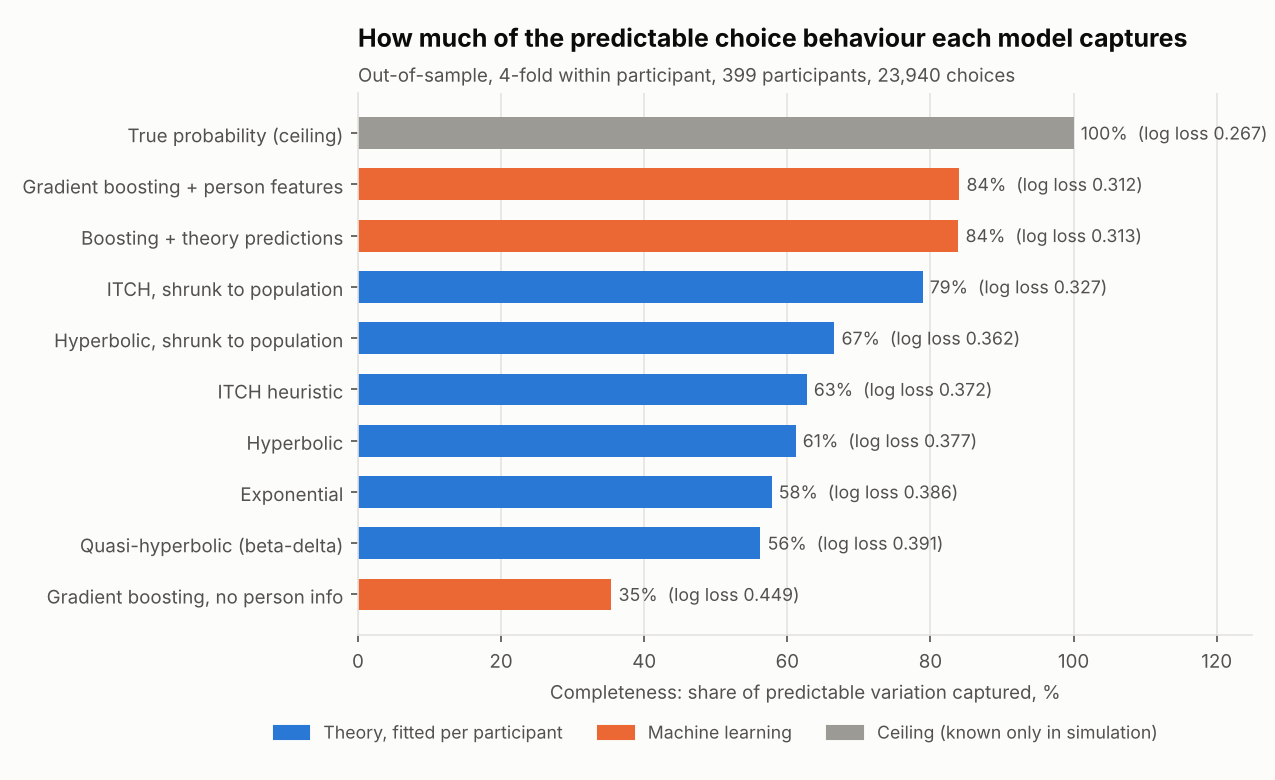

In [6]:
R.plot_completeness(board, Path("outputs/figures/completeness.png"))
display(Image("outputs/figures/completeness.png"))

## Where the machine-learning advantage comes from

Without person information, gradient boosting is the second-worst model. With each person's base
rate and fitted parameters it is the best. So the gain is mostly about pooling information across
people, not about a better rule for trading money against time. Shrinking each person's ITCH
estimates towards the population, a simple empirical-Bayes step, recovers most of the gap.

In [7]:
for a, b in [("itch", "hyperbolic"), ("itch_eb", "ml_person"), ("hybrid", "ml_person")]:
    d, lo, hi = E.bootstrap_ci(cv, a, b)
    print(f"{a:>10} minus {b:<10} log loss {d:+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")

      itch minus hyperbolic log loss -0.0044  (95% CI -0.0172 to +0.0084)
   itch_eb minus ml_person  log loss +0.0145  (95% CI +0.0092 to +0.0198)
    hybrid minus ml_person  log loss +0.0004  (95% CI -0.0022 to +0.0028)


## By true decision type

Discounting models capture little of what heuristic users do. For those participants, shrunk ITCH is
the best model of all, ahead of gradient boosting.

In [8]:
(E.by_type(cv, tables["truth"]) * 100).round(0)

model,exponential,hyperbolic,itch,itch_eb,ml_person,quasi_hyperbolic
true_type,,,,,,
exponential,68.0,67.0,61.0,77.0,83.0,60.0
hyperbolic,68.0,73.0,62.0,77.0,88.0,63.0
itch,28.0,34.0,76.0,87.0,83.0,41.0
quasi_hyperbolic,64.0,64.0,53.0,74.0,79.0,57.0
